[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C4_NB07_criticality_chaos.ipynb)

# Day 2 · Chapter 4 · Notebook 07 — Criticality and chaos: small causes, big effects

Two ways in which a tiny cause has a huge effect: **criticality**, where one spike can start a cascade of any size
(Part A), and **chaos**, where a tiny difference in the start changes the whole future (Part B). Watch what changes
when the branching ratio $\sigma$ crosses 1, and how fast two almost identical runs separate.

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from matplotlib.colors import LinearSegmentedColormap
REG = {"sub": "0.35", "crit": "C0", "super": "C3"}   # colours: subcritical grey, critical blue, supercritical red

# Part A · Criticality

## 1. One spike, and its children

Each spike makes, on average, $\sigma$ new spikes in the next step (the **branching ratio**, the knob of the slides).
We start 10 of 5000 neurons and follow the activity.

<details><summary>The model (for the curious)</summary>

$N = 5000$ neurons, all connected. Each spike has a random number of "children" (Poisson, mean $\sigma$), each a
random neuron that fires in the next step. In a real network $\sigma = p\,(N-1)$, with $p$ the probability that a
spike makes a given neuron fire: only $p\approx1/N$ gives $\sigma\approx1$ (Shew & Plenz 2013).
</details>

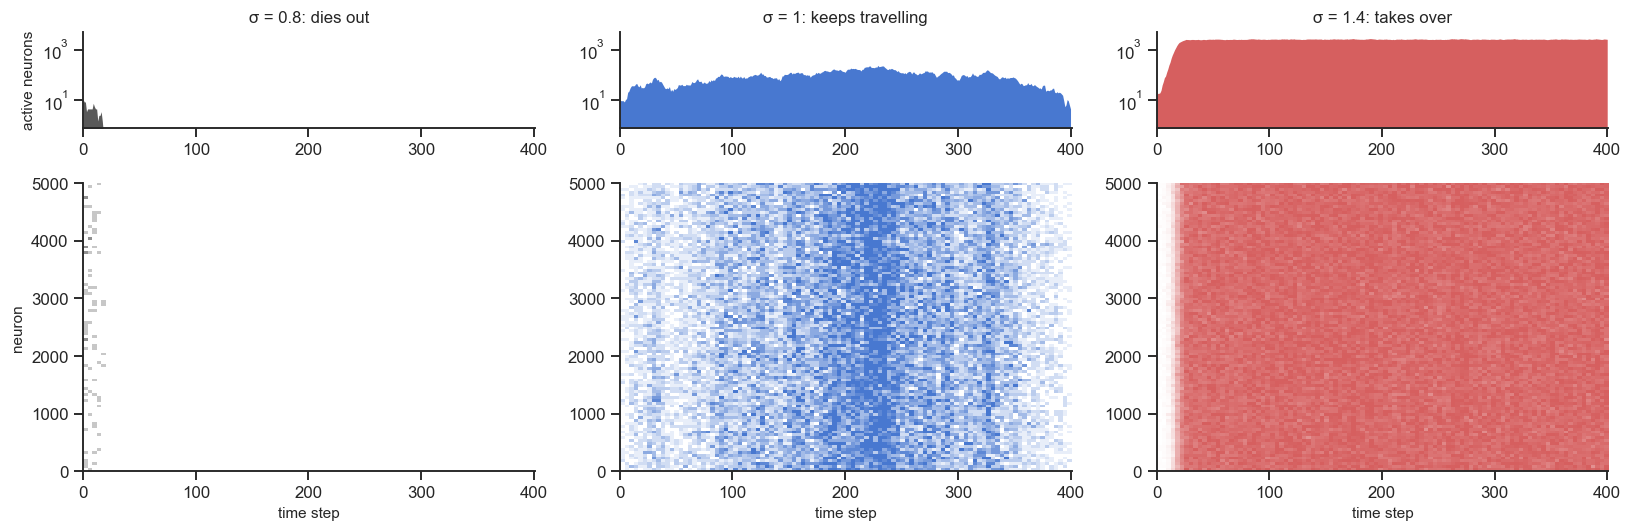

In [2]:
# @title Branching network: one run below (σ = 0.8), at (σ = 1) and above (σ = 1.4) the critical point
N_NET = 5000
def run_net(sigma, T=400, A0=10, seed=0):
    # raster (neurons x time steps), started by A0 active neurons
    rng = np.random.default_rng(seed)
    s = np.zeros(N_NET, bool); s[rng.choice(N_NET, A0, replace=False)] = True; out = [s]
    for t in range(T):
        children = rng.integers(N_NET, size=rng.poisson(sigma * s.sum()))   # each spike has on average sigma children
        s = np.zeros(N_NET, bool); s[children] = True; out.append(s)
    return np.array(out).T

def binned(R, bn=50, bt=4):                                             # spikes per block of 50 neurons x 4 steps
    n, T = R.shape; T = T // bt * bt
    return R[:, :T].reshape(n // bn, bn, T // bt, bt).sum(axis=(1, 3))

def example(sigma, want):                                               # an example run of each kind (critical: one that survived)
    for seed in range(3000):
        R = run_net(sigma, seed=seed); a = R.sum(0); last = np.nonzero(a)[0].max()
        if (want == "sub" and 15 <= last <= 40) or (want == "crit" and last == R.shape[1] - 1 and a.max() < 300) or (want == "super" and a[-1] > 0):
            return R
    return R

def raster_panel(ax_top, ax_bot, R, colour, title):
    T = R.shape[1]
    ax_top.fill_between(np.arange(T), R.sum(0) + 0.5, 0.5, color=colour, lw=0)
    ax_top.set(yscale="log", ylim=(0.8, N_NET), xlim=(0, T), title=title)
    cm = LinearSegmentedColormap.from_list("w", ["white", colour])
    B = binned(R); vmax = max(3, np.percentile(B[B > 0], 90)) if B.any() else 3   # colour scale adapted to the run
    ax_bot.imshow(B, aspect="auto", origin="lower", cmap=cm, vmin=0, vmax=vmax, extent=(0, T, 0, N_NET), interpolation="nearest")
    ax_bot.set(xlabel="time step")

CASES = [(0.8, "sub", "σ = 0.8: dies out"), (1.0, "crit", "σ = 1: keeps travelling"), (1.4, "super", "σ = 1.4: takes over")]
fig, ax = plt.subplots(2, 3, figsize=(15, 5), gridspec_kw=dict(height_ratios=[1, 3]))
for j, (sig, key, name) in enumerate(CASES):
    raster_panel(ax[0, j], ax[1, j], example(sig, key), REG[key], name)
ax[0, 0].set_ylabel("active neurons"); ax[1, 0].set_ylabel("neuron")
plt.tight_layout(); plt.show()

Bottom: the 5000 neurons over time (darker = more spikes); top: number of active neurons (log scale).
**Grey:** the activity fades. **Red:** it invades the network and stays, like a seizure. **Blue:** it wanders for
hundreds of steps without dying or taking over.

### Explore: the branching ratio
* Move $\sigma$ slowly through 1. One run can die by chance even above 1; the right panel shows how many of 2000
  runs survive.

In [3]:
# @title Explore: one run and the survival of 2000 runs, for any branching ratio
def run_counts(sigma, T, n_runs, A0=10, h=0.0, seed=0):
    # same network, only the number of active neurons, for many runs at once (h = outside input per neuron per step)
    rng = np.random.default_rng(seed); A = np.full(np.broadcast(n_runs, sigma, h).shape, A0); out = [A]
    for t in range(T):
        A = rng.binomial(N_NET, 1 - np.exp(-sigma * A / N_NET - h)); out.append(A)
    return np.array(out)

SEED = next(k for k in range(3000) if run_net(1.0, seed=k)[:, -1].any())   # a run that survives at σ = 1, reused for every σ

@interact(sigma=slider(1.0, 0.5, 1.5, 0.05, "branching ratio σ"))
def explore_sigma(sigma):
    key = "sub" if sigma < 0.98 else "super" if sigma > 1.02 else "crit"
    fig, ax = plt.subplots(2, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[2, 1], height_ratios=[1, 3]))
    raster_panel(ax[0, 0], ax[1, 0], run_net(sigma, seed=SEED), REG[key], f"one run, σ = {sigma:.2f}")
    ax[0, 0].set_ylabel("active neurons"); ax[1, 0].set_ylabel("neuron")
    ax[0, 1].axis("off"); A = run_counts(sigma, 400, np.zeros(2000))
    ax[1, 1].plot((A > 0).mean(1), c=REG[key]); ax[1, 1].set(yscale="log", ylim=(1e-3, 1.1), xlabel="time step", ylabel="fraction of runs still active", title="2000 runs")
    plt.tight_layout(); plt.show()

## 2. Avalanches: no typical size

We start 100 000 cascades from **one** spike and count the **size** of each (total number of spikes). At $\sigma=1$
there is no typical size: on log–log axes the distribution is a straight line, a **power law**, the signature looked
for in real brains (Beggs & Plenz 2003; in human EEG in NB09).

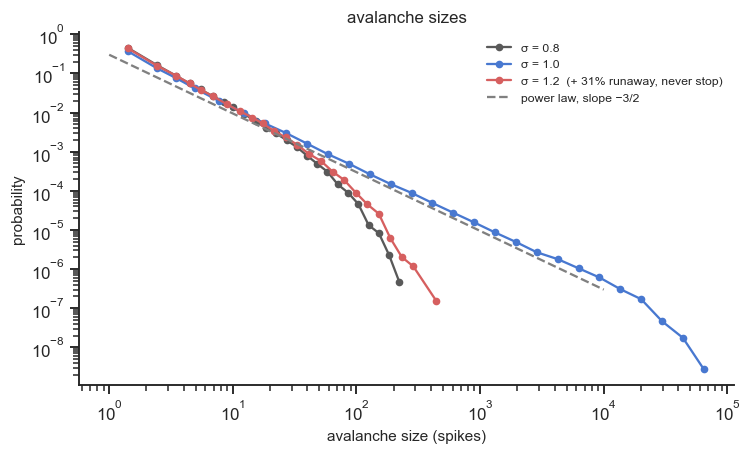

In [4]:
# @title Avalanche sizes from 100 000 cascades started by one spike, below, at and above σ = 1
def avalanche_sizes(sigma, n=100_000, T=2000, seed=1):
    rng = np.random.default_rng(seed); A = np.ones(n, int); size = A.copy()
    for t in range(T):
        live = A > 0                                                     # only active cascades need updating
        A[live] = rng.binomial(N_NET, 1 - np.exp(-sigma * A[live] / N_NET)); size += A
    ended = A == 0                                                       # cascades that stopped within T steps
    return size[ended], 1 - ended.mean()

def log_hist(x, n_bins=30):
    edges = np.unique(np.logspace(0, np.log10(x.max() + 1), n_bins).astype(int)); h, _ = np.histogram(x, edges)
    c = np.sqrt(edges[:-1] * edges[1:]); ok = h > 0
    return c[ok], (h / np.diff(edges) / len(x))[ok]

fig, ax = plt.subplots(figsize=(7, 4.3))
for sig, key in [(0.8, "sub"), (1.0, "crit"), (1.2, "super")]:
    sizes, runaway = avalanche_sizes(sig)
    lab = f"σ = {sig}" + (f"  (+ {100 * runaway:.0f}% runaway, never stop)" if runaway > 0.01 else "")
    xs, P = log_hist(sizes); ax.plot(xs, P, "o-", ms=4, c=REG[key], label=lab)
xx = np.logspace(0, 4, 10); ax.plot(xx, 0.3 * xx ** -1.5, "--", c="0.5", label="power law, slope −3/2")
ax.set(xscale="log", yscale="log", xlabel="avalanche size (spikes)", ylabel="probability", title="avalanche sizes")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Grey: only small avalanches. Blue: a straight line over four decades. Red: small avalanches, plus runaway
cascades that never stop (not in the histogram).

<details><summary>Power laws, scale invariance, universality (for the curious)</summary>

$P(s)\propto s^{-3/2}$: an avalanche 10 times bigger is $10^{3/2}\approx32$ times rarer, whatever size you start from,
so every zoom of the curve looks the same (**scale invariance**); an exponential decay instead has a typical size.
The exponent does not depend on the details: slope about $-3/2$ is found in this model, in cortical slices and in
awake monkeys (one **universality class**; Petermann et al. 2009). A power law alone does not prove criticality,
which is why functional tests (next section) matter.
</details>

## 3. Why sit at σ = 1: the widest range of inputs

Drive the network with outside input, from very weak to very strong, and measure the response (fraction of neurons
active). The **dynamic range** is the span of input intensities that the response can tell apart.

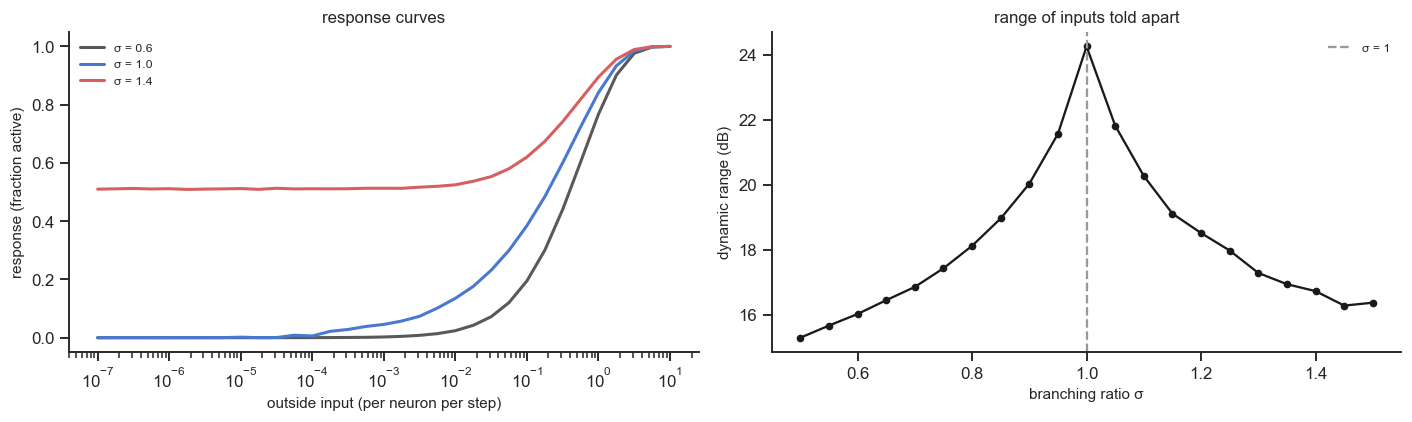

In [5]:
# @title Response to outside input and dynamic range, for many branching ratios (a few seconds)
hs = np.logspace(-7, 1, 33)                                              # outside input per neuron per step
sig_scan = np.round(np.arange(0.5, 1.501, 0.05), 2)
A0 = np.where(sig_scan[:, None] > 1, N_NET // 2, 0) * np.ones((1, hs.size), int)   # supercritical: start in its own active state
A = run_counts(sig_scan[:, None], 600, np.zeros((sig_scan.size, hs.size)), A0=A0, h=hs[None, :], seed=2)
F = A[200:].mean(0) / N_NET                                              # mean response after a transient

def dynamic_range(F, hs):                                                # dB of input between 10% and 90% of the response
    lo, hi = F[0] + 0.1 * (F[-1] - F[0]), F[0] + 0.9 * (F[-1] - F[0])
    return 10 * np.log10(10 ** np.interp(hi, F, np.log10(hs)) / 10 ** np.interp(lo, F, np.log10(hs)))
DR = np.array([dynamic_range(f, hs) for f in F])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for sig, key in [(0.6, "sub"), (1.0, "crit"), (1.4, "super")]:
    i = np.argmin(abs(sig_scan - sig)); ax[0].semilogx(hs, F[i], c=REG[key], lw=2, label=f"σ = {sig}")
ax[0].set(xlabel="outside input (per neuron per step)", ylabel="response (fraction active)", title="response curves"); ax[0].legend(fontsize=8)
ax[1].plot(sig_scan, DR, "ko-", ms=4); ax[1].axvline(1, c="0.6", ls="--", label="σ = 1")
ax[1].set(xlabel="branching ratio σ", ylabel="dynamic range (dB)", title="range of inputs told apart"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Left: the subcritical network (grey) ignores weak inputs; the supercritical one (red) is busy with its own activity
and barely notices them; the critical one (blue) responds to inputs about a hundred times weaker. Right: the dynamic
range peaks at $\sigma=1$: at the balance point the network is most **sensitive**, like any system near a bifurcation
(slides, NB08).

<details><summary>More benefits, and the evidence in real brains (for the curious)</summary>

Dynamic range = 10·log₁₀ of the ratio between the inputs giving 10% and 90% of the response change (Kinouchi &
Copelli 2006). The **information transmitted** between sites and the **repertoire** of distinct patterns also peak
near $\sigma=1$. In cortex, dynamic range and information peak when drugs bring the excitation–inhibition balance
to the point where avalanches are power laws (Shew et al. 2009, 2011; Shew & Plenz 2013).
</details>

# Part B · Chaos

## 4. A tiny difference, a different future

Four rotators (NB04), each with its own speed, pulled together with strength $K$, **without noise**. In 1961 Lorenz
restarted a weather simulation from a printout with 3 decimals instead of 6 and got a different "weather". We do the
same, and follow two runs that start $10^{-8}$ apart.

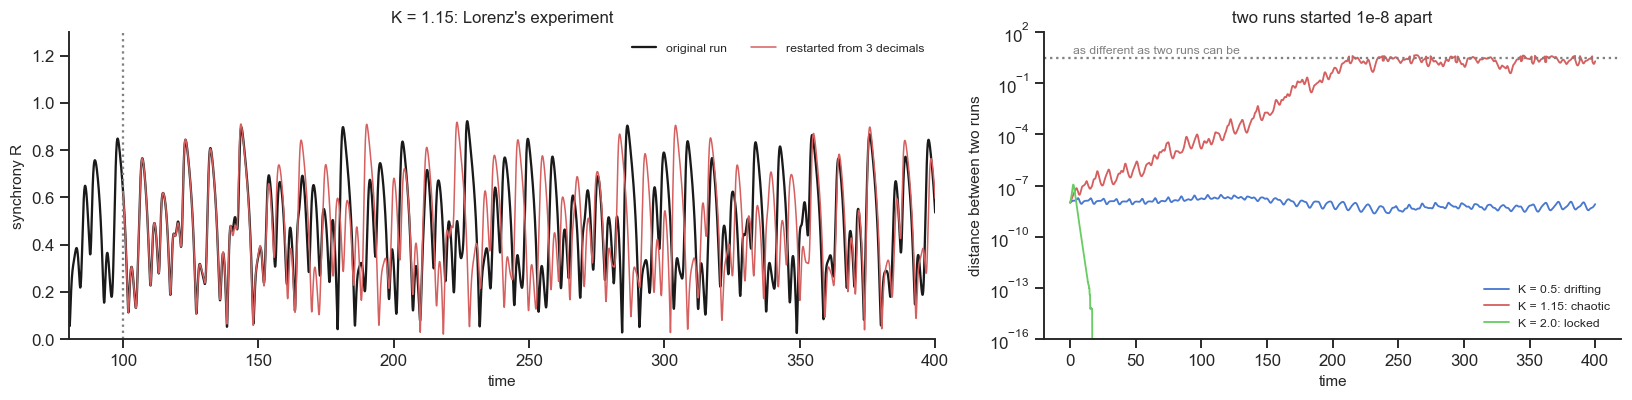

In [6]:
# @title Four coupled rotators: restart from 3 decimals (left) and growth of a 1e-8 difference (right)
def kuramoto4(theta0, K, T=300.0, dt=0.05):
    # d theta_j/dt = omega_j + K/N sum_k sin(theta_k - theta_j), integrated with Runge-Kutta 4 (accurate)
    theta0 = np.asarray(theta0, float); N = theta0.shape[-1]; omega = np.linspace(-1, 1, N)
    speed = lambda th: omega + K / N * np.sin(th[..., None, :] - th[..., :, None]).sum(-1)
    n = int(round(T / dt)); out = np.empty((n + 1,) + theta0.shape); out[0] = th = theta0
    for i in range(n):
        k1 = speed(th); k2 = speed(th + dt / 2 * k1); k3 = speed(th + dt / 2 * k2); k4 = speed(th + dt * k3)
        out[i + 1] = th = th + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return np.arange(n + 1) * dt, out
order_R = lambda th: np.abs(np.exp(1j * th).mean(-1))                  # synchrony R (NB04): 1 together, 0 spread
def distance(a, b):                                                    # how different two runs are (ignoring a common shift)
    d = np.angle(np.exp(1j * (b - a))); d = d - d.mean(-1, keepdims=True); return np.sqrt((d ** 2).sum(-1))

rng = np.random.default_rng(0)
_, warm = kuramoto4(rng.uniform(0, 2 * np.pi, 4), K=1.15, T=200); START = warm[-1]
NUDGE = rng.standard_normal(4); NUDGE -= NUDGE.mean(); NUDGE /= np.linalg.norm(NUDGE)
CH = {0.5: ("drifting", "C0"), 1.15: ("chaotic", "C3"), 2.0: ("locked", "C2")}

t_print = 100
t, th = kuramoto4(START, 1.15, T=t_print + 300)
printed = np.round(np.mod(th[int(t_print / 0.05)], 2 * np.pi), 3)      # the "printout"
t2, th2 = kuramoto4(printed, 1.15, T=300)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax[0].plot(t, order_R(th), "k", lw=1.5, label="original run"); ax[0].plot(t_print + t2, order_R(th2), "C3", lw=1, label="restarted from 3 decimals")
ax[0].axvline(t_print, c="gray", ls=":"); ax[0].set(xlabel="time", ylabel="synchrony R", xlim=(t_print - 20, t_print + 300), ylim=(0, 1.3),
                                                     title="K = 1.15: Lorenz's experiment")
ax[0].legend(loc="upper right", fontsize=8, ncol=2)
for Kc, (name, col) in CH.items():
    t, th = kuramoto4(np.stack([START, START + 1e-8 * NUDGE]), Kc, T=400)
    ax[1].semilogy(t, np.maximum(distance(th[:, 0], th[:, 1]), 1e-16), col, lw=1.2, label=f"K = {Kc}: {name}")
ax[1].axhline(np.pi, c="gray", ls=":"); ax[1].text(2, 5, "as different as two runs can be", fontsize=8, color="gray")
ax[1].set(xlabel="time", ylabel="distance between two runs", ylim=(1e-16, 100), title="two runs started 1e-8 apart")
ax[1].legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

Left: the two runs overlap for a while, then are unrelated: a difference below 0.001 changed the future (the
**butterfly effect**). Right (log axis): locked rotators forget the difference, drifting ones keep it small, chaotic
ones make it grow **exponentially** (a straight line). Chaos looks like noise, but rerun the cell: the curves are identical.

<details><summary>Lyapunov exponent and prediction horizon (for the curious)</summary>

The slope of the straight line is the **Lyapunov exponent** $\lambda$: error $\approx d_0\,e^{\lambda t}$; chaos means
$\lambda>0$. A forecast holds until the error reaches a tolerance, at $t\approx\frac1\lambda\ln(\text{tolerance}/d_0)$:
a start measured a billion times more precisely adds only $\ln(10^9)/\lambda\approx21/\lambda$ (why weather forecasts
stop at about two weeks). Chaos needs at least three independent directions: 4 rotators have three phase differences.
</details>

### Explore: where are the rotators chaotic?
* Move $K$ from 0.3 to 2.5. For which values do the two runs separate?

In [7]:
# @title Explore: two runs started 1e-8 apart, for any coupling K
@interact(K=slider(1.15, 0.3, 2.5, 0.05, "coupling K"))
def explore_chaos(K):
    t, th = kuramoto4(np.stack([START, START + 1e-8 * NUDGE]), K, T=400)
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
    ax[0].plot(t, order_R(th[:, 0]), "k", lw=1.5, label="run 1"); ax[0].plot(t, order_R(th[:, 1]), "C3", lw=1, label="run 2 (nudged by 1e-8)")
    ax[0].set(xlabel="time", ylabel="synchrony R", ylim=(0, 1.3)); ax[0].legend(fontsize=8, ncol=2)
    ax[1].semilogy(t, np.maximum(distance(th[:, 0], th[:, 1]), 1e-16), "k")
    ax[1].set(xlabel="time", ylabel="distance between the runs", ylim=(1e-16, 100))
    plt.tight_layout(); plt.show()

## Take-home

* **Criticality:** at $\sigma=1$ one spike can trigger avalanches of any size (a power law), and the network
  responds to the widest range of inputs.
* **Chaos:** deterministic does not mean predictable; tiny differences grow exponentially. Four units are enough.
* **Next (NB08):** the bifurcations inside the models of the course.

### Homework
*At home, after the class.*
1. **Estimate σ from data.** With `run_counts`, record cascades at $\sigma = 0.8, 1, 1.2$ and average the ratio
   (spikes at step $t+1$)/(spikes at step $t$). Do you recover $\sigma$?
2. **Chaos or noise?** Add a tiny noise ($10^{-6}$) to `kuramoto4` and run the chaotic rotators twice from the same
   start with different seeds. When do the runs separate?
3. **The chaotic window.** Measure the Lyapunov exponent for $K$ from 0.5 to 2. Repeat with 3 rotators.

### References
* Beggs JM, Plenz D (2003). Neuronal avalanches in neocortical circuits. *J Neurosci* 23:11167–11177.
* Kinouchi O, Copelli M (2006). Optimal dynamical range of excitable networks at criticality. *Nat Phys* 2:348–351.
* Shew WL et al. (2009) *J Neurosci* 29:15595. Shew WL et al. (2011) *J Neurosci* 31:55. Petermann T et al. (2009)
  *PNAS* 106:15921.
* Shew WL, Plenz D (2013). The functional benefits of criticality in the cortex. *Neuroscientist* 19:88–100.
* Lorenz EN (1963). Deterministic nonperiodic flow. *J Atmos Sci* 20:130–141.
* Strogatz SH (2015). *Nonlinear Dynamics and Chaos*, 2nd ed. Westview Press. (Ch. 9–10.)